In [10]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
%config InlineBackend.figure_format='retina'
import sys; print(sys.version)
sys.path.append('python-src')
from import_all_notebook_hook import *
import fastbook
fastbook.setup_book()
from fastbook import *

3.8.10 (default, Jun  4 2021, 15:09:15) 
[GCC 7.5.0]


## Dataset choosing

In [11]:
pth='./dataset-cls'
pth='./dataset-test/cls-preproc'
#pth='./dataset-test/cls-margin-preproc'
#pth='./dataset-cls-margin60'

## Dataset metrics (n_train, n_valid, labels)

In [12]:
def f_is_valid(fn): return 'cls_test' == fn.parent.parent.name
def f_class(fn): return fn.parent.name

fns = get_image_files(pth)
is_valid = [f_is_valid(x) for x in fns]

print(f'Training samples =  {len(is_valid)-sum(is_valid)} Validation sample = {sum(is_valid)}')
print(f'Training classes: {Counter(map(f_class,filter(lambda x: not f_is_valid(x),fns)))}')
print(f'Valid classes: {Counter(map(f_class,filter(f_is_valid,fns)))}')


Training samples =  90 Validation sample = 0
Training classes: Counter({'no-signature': 40, 'yes-signature': 34, 'linea': 16})
Valid classes: Counter()


In [13]:
labels = sorted(list(set(map(f_class,fns))))
labels

['linea', 'no-signature', 'yes-signature']

In [14]:
train_fns = [ fn for fn in fns if not(f_is_valid(fn)) ]
valid_fns = [ fn for fn in fns if f_is_valid(fn) ]
train_cls = [ f_class(fn) for fn in train_fns ]
valid_cls = [ f_class(fn) for fn in valid_fns ]
assert len(train_fns)==len(train_cls)
assert len(valid_fns)==len(valid_cls)
len(train_fns), len(valid_cls)

(90, 0)

## Choose the predictor

The predictor should be a function from Signature name file -> {yes-signature, no-signature, linea}

In [15]:
def naive_pred(fn):
    img = Image.open(fn)
    img = Image.fromarray(naive_preprocess_signature(np.array(img)))
    return 'yes-signature' if naive_is_signature(img) else 'no-signature'

predictor_used = naive_pred

## Accuracy

In [16]:
def accuracy(cls, preds): return sum([a==b for a,b in zip(cls,preds)])/len(preds)

In [17]:
preds_train = parallel_fmap(predictor_used, train_fns)

  0%|          | 0/90 [00:00<?, ?it/s]/home/marian/Escritorio/trabajo/deteccion-firmas/python-src/telegramas_crop_signatures.py:187: FutureWarning: The new recommended value for bg_label is 0. Until version 0.19, the default bg_label value is -1. From version 0.19, the bg_label default value will be 0. To avoid this warning, please explicitly set bg_label value.
  image_label_overlay = label2rgb(blobs_labels, image=np_img)
/home/marian/Escritorio/trabajo/deteccion-firmas/python-src/telegramas_crop_signatures.py:187: FutureWarning: The new recommended value for bg_label is 0. Until version 0.19, the default bg_label value is -1. From version 0.19, the bg_label default value will be 0. To avoid this warning, please explicitly set bg_label value.
  image_label_overlay = label2rgb(blobs_labels, image=np_img)
/home/marian/Escritorio/trabajo/deteccion-firmas/python-src/telegramas_crop_signatures.py:187: FutureWarning: The new recommended value for bg_label is 0. Until version 0.19, the defau

In [18]:
preds_valid = parallel_fmap(predictor_used, valid_fns)

0it [00:00, ?it/s]


In [19]:
train_acc = accuracy(train_cls,preds_train)
print(f'Train acc: {train_acc}') 

Train acc: 0.6777777777777778


In [20]:
valid_acc = accuracy(valid_cls,preds_valid)
print(f'Valid acc: {valid_acc}')

ZeroDivisionError: division by zero

## Confusion matrix

rows = label , columns = prediction

- matix\[no-signature\]\[yes-signature\] are non captured empty holes (false negative of the alarm) matix\[1\]\[2\]
- matix\[yes-signature\]\[no-signature\] are false alarms (false positive of the alarm) matix\[2\]\[1\]

In [26]:
labels

['linea', 'no-signature', 'yes-signature']

In [42]:
from sklearn.metrics import confusion_matrix
# Train confusion matrix
# 
confusion_matrix(train_cls, preds_train, labels=list(labels))

array([[ 0,  7,  9],
       [ 0, 33,  7],
       [ 0,  6, 28]])

In [30]:
# Valid confusion matrix
confusion_matrix(valid_cls, preds_valid, labels=list(labels))

array([[0, 0, 0],
       [0, 0, 0],
       [0, 0, 0]])

## Error visualization

- no_misconfused: non captured error
- yes_misconfused: false alarms

In [46]:
def plot_some(fns,cnt=None):
    truncated = fns[:cnt]
    imgs=[Image.open(fn) for fn in truncated]
    plot_images_grid(imgs,2,truncated,figsize=(30,30))

def calc_misconfused(fns, cls, preds, cls_filtered):
    return [fns[i] for i in range(len(fns)) if cls[i]==cls_filtered and preds[i]!=cls[i] ]

In [47]:
no_misconfused = calc_misconfused(train_fns, train_cls, preds_train, 'no-signature')
yes_misconfused = calc_misconfused(train_fns, train_cls, preds_train, 'yes-signature')

In [48]:
print('Non captured errors: {}'.format(len(yes_misconfused)))
print('False alarms: {}'.format(len(no_misconfused)))

Non captured errors: 6
False alarms: 7


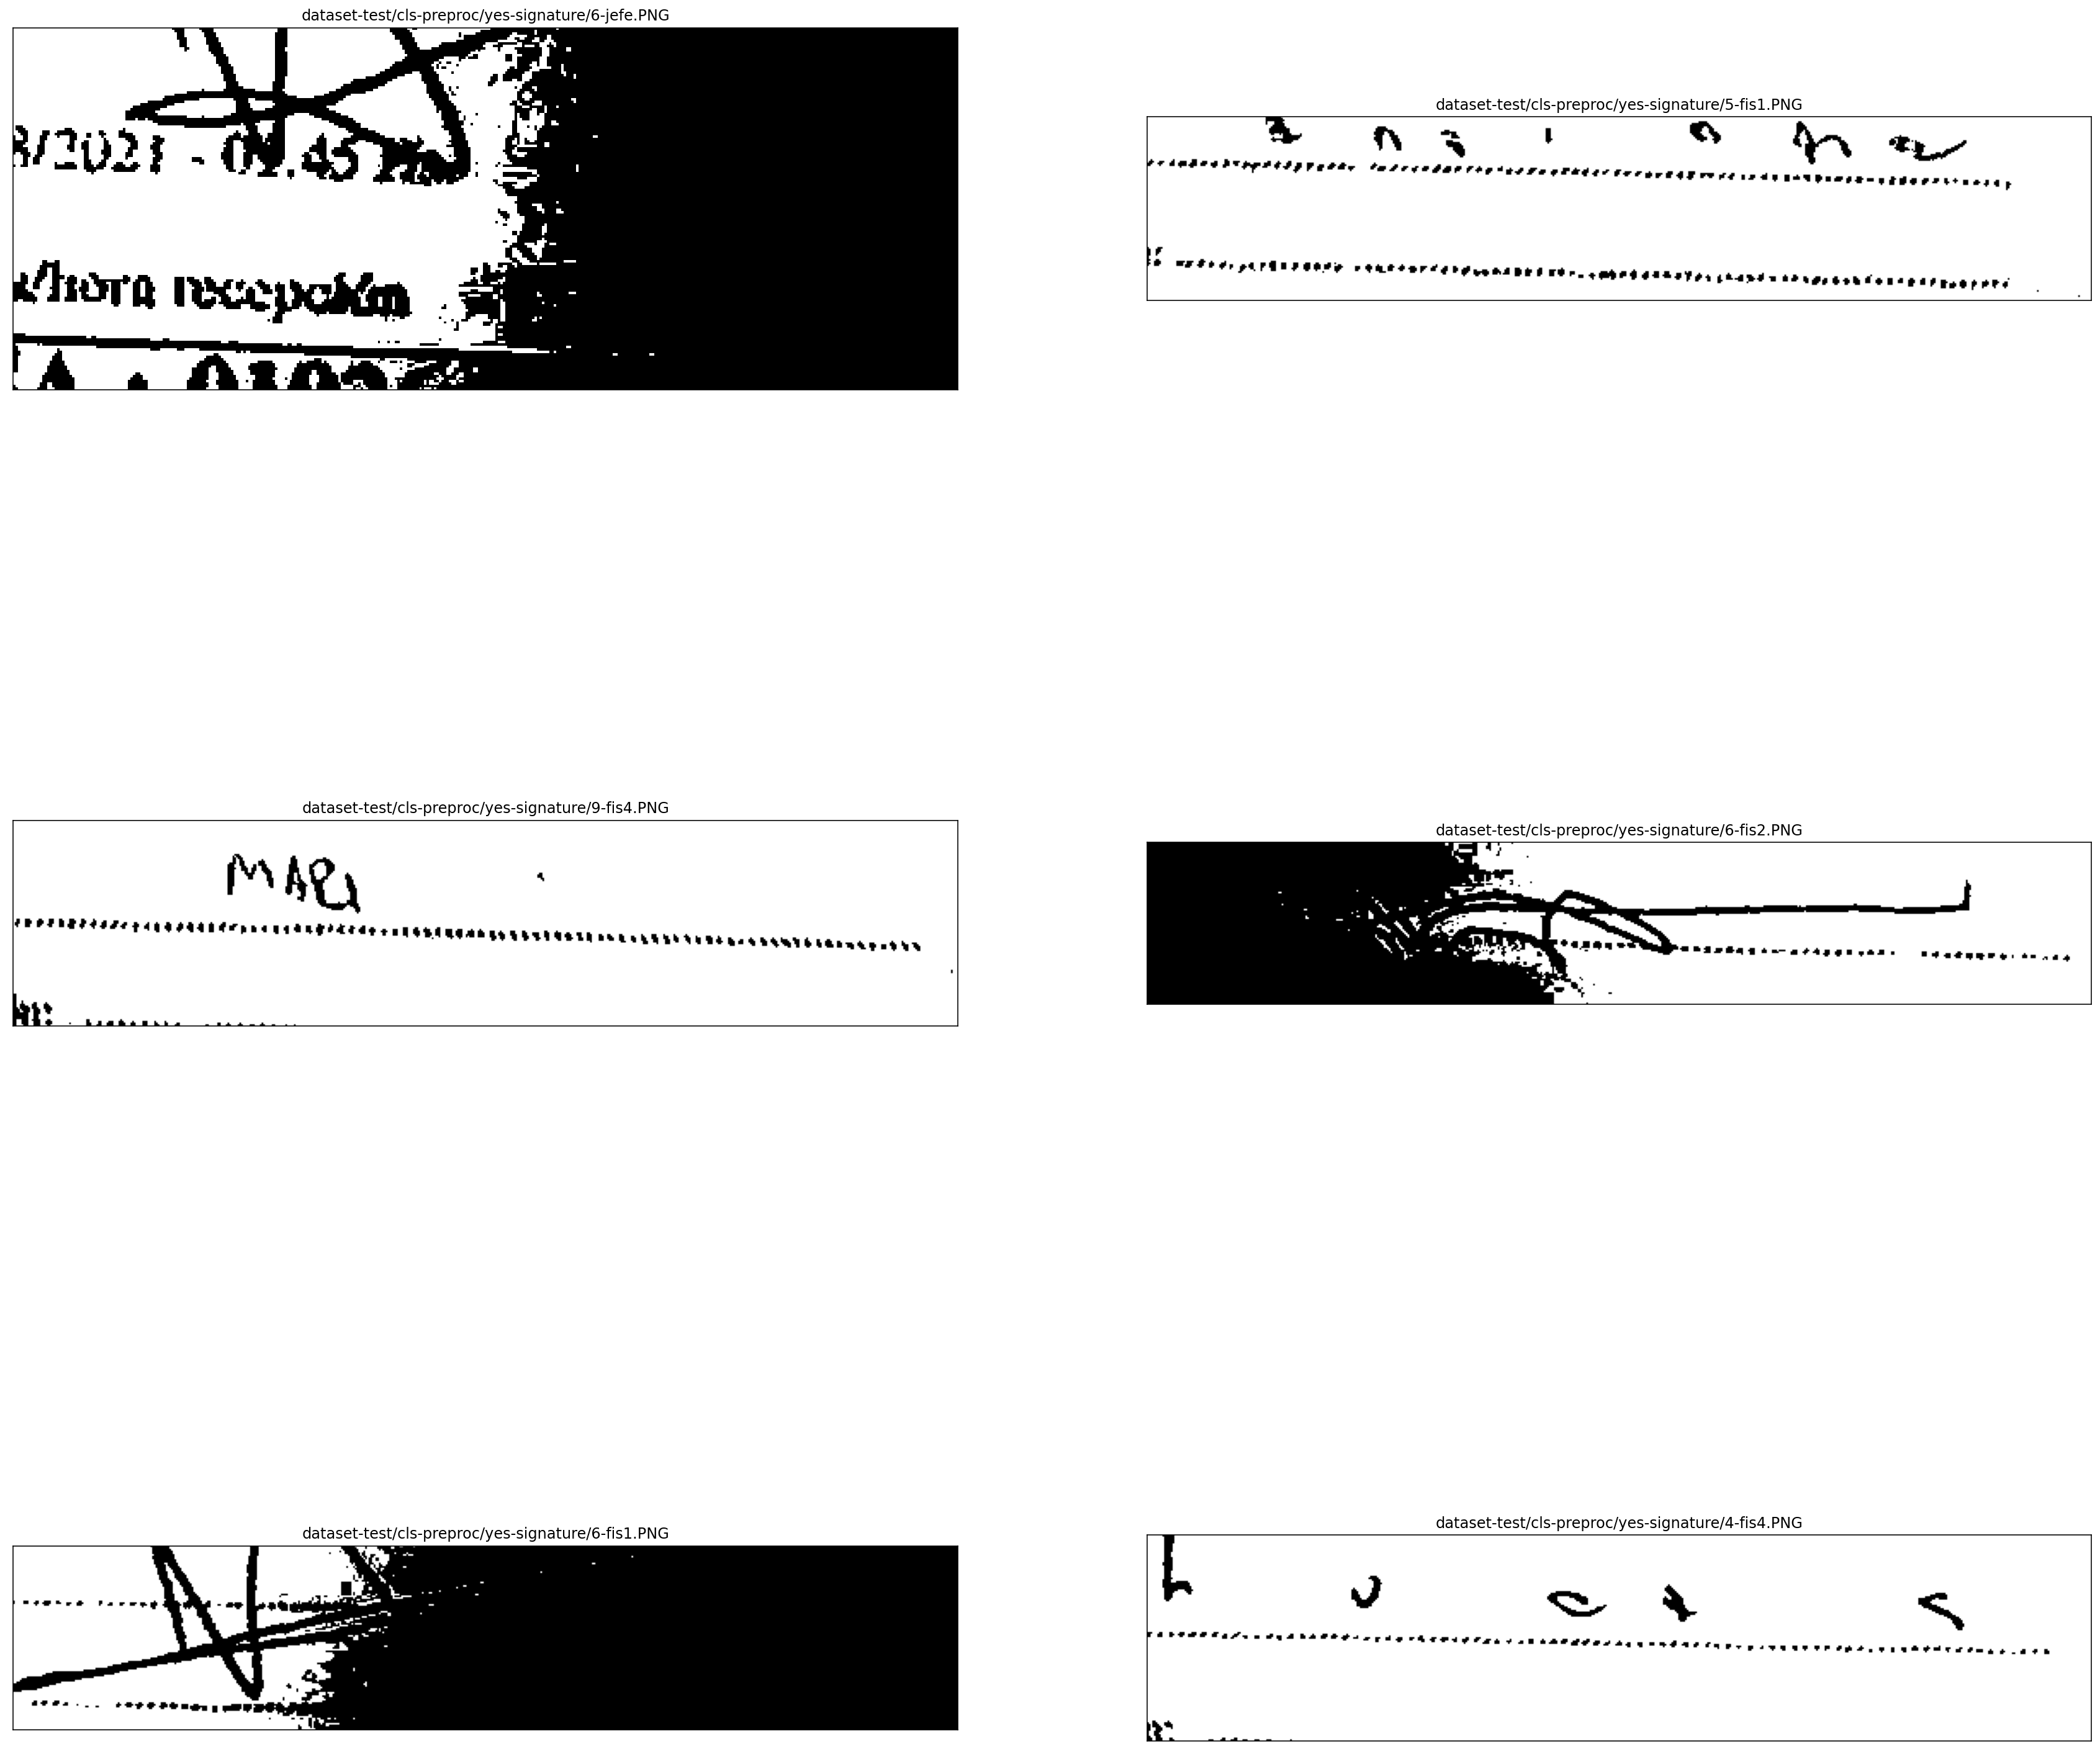

In [49]:
plot_some(yes_misconfused)

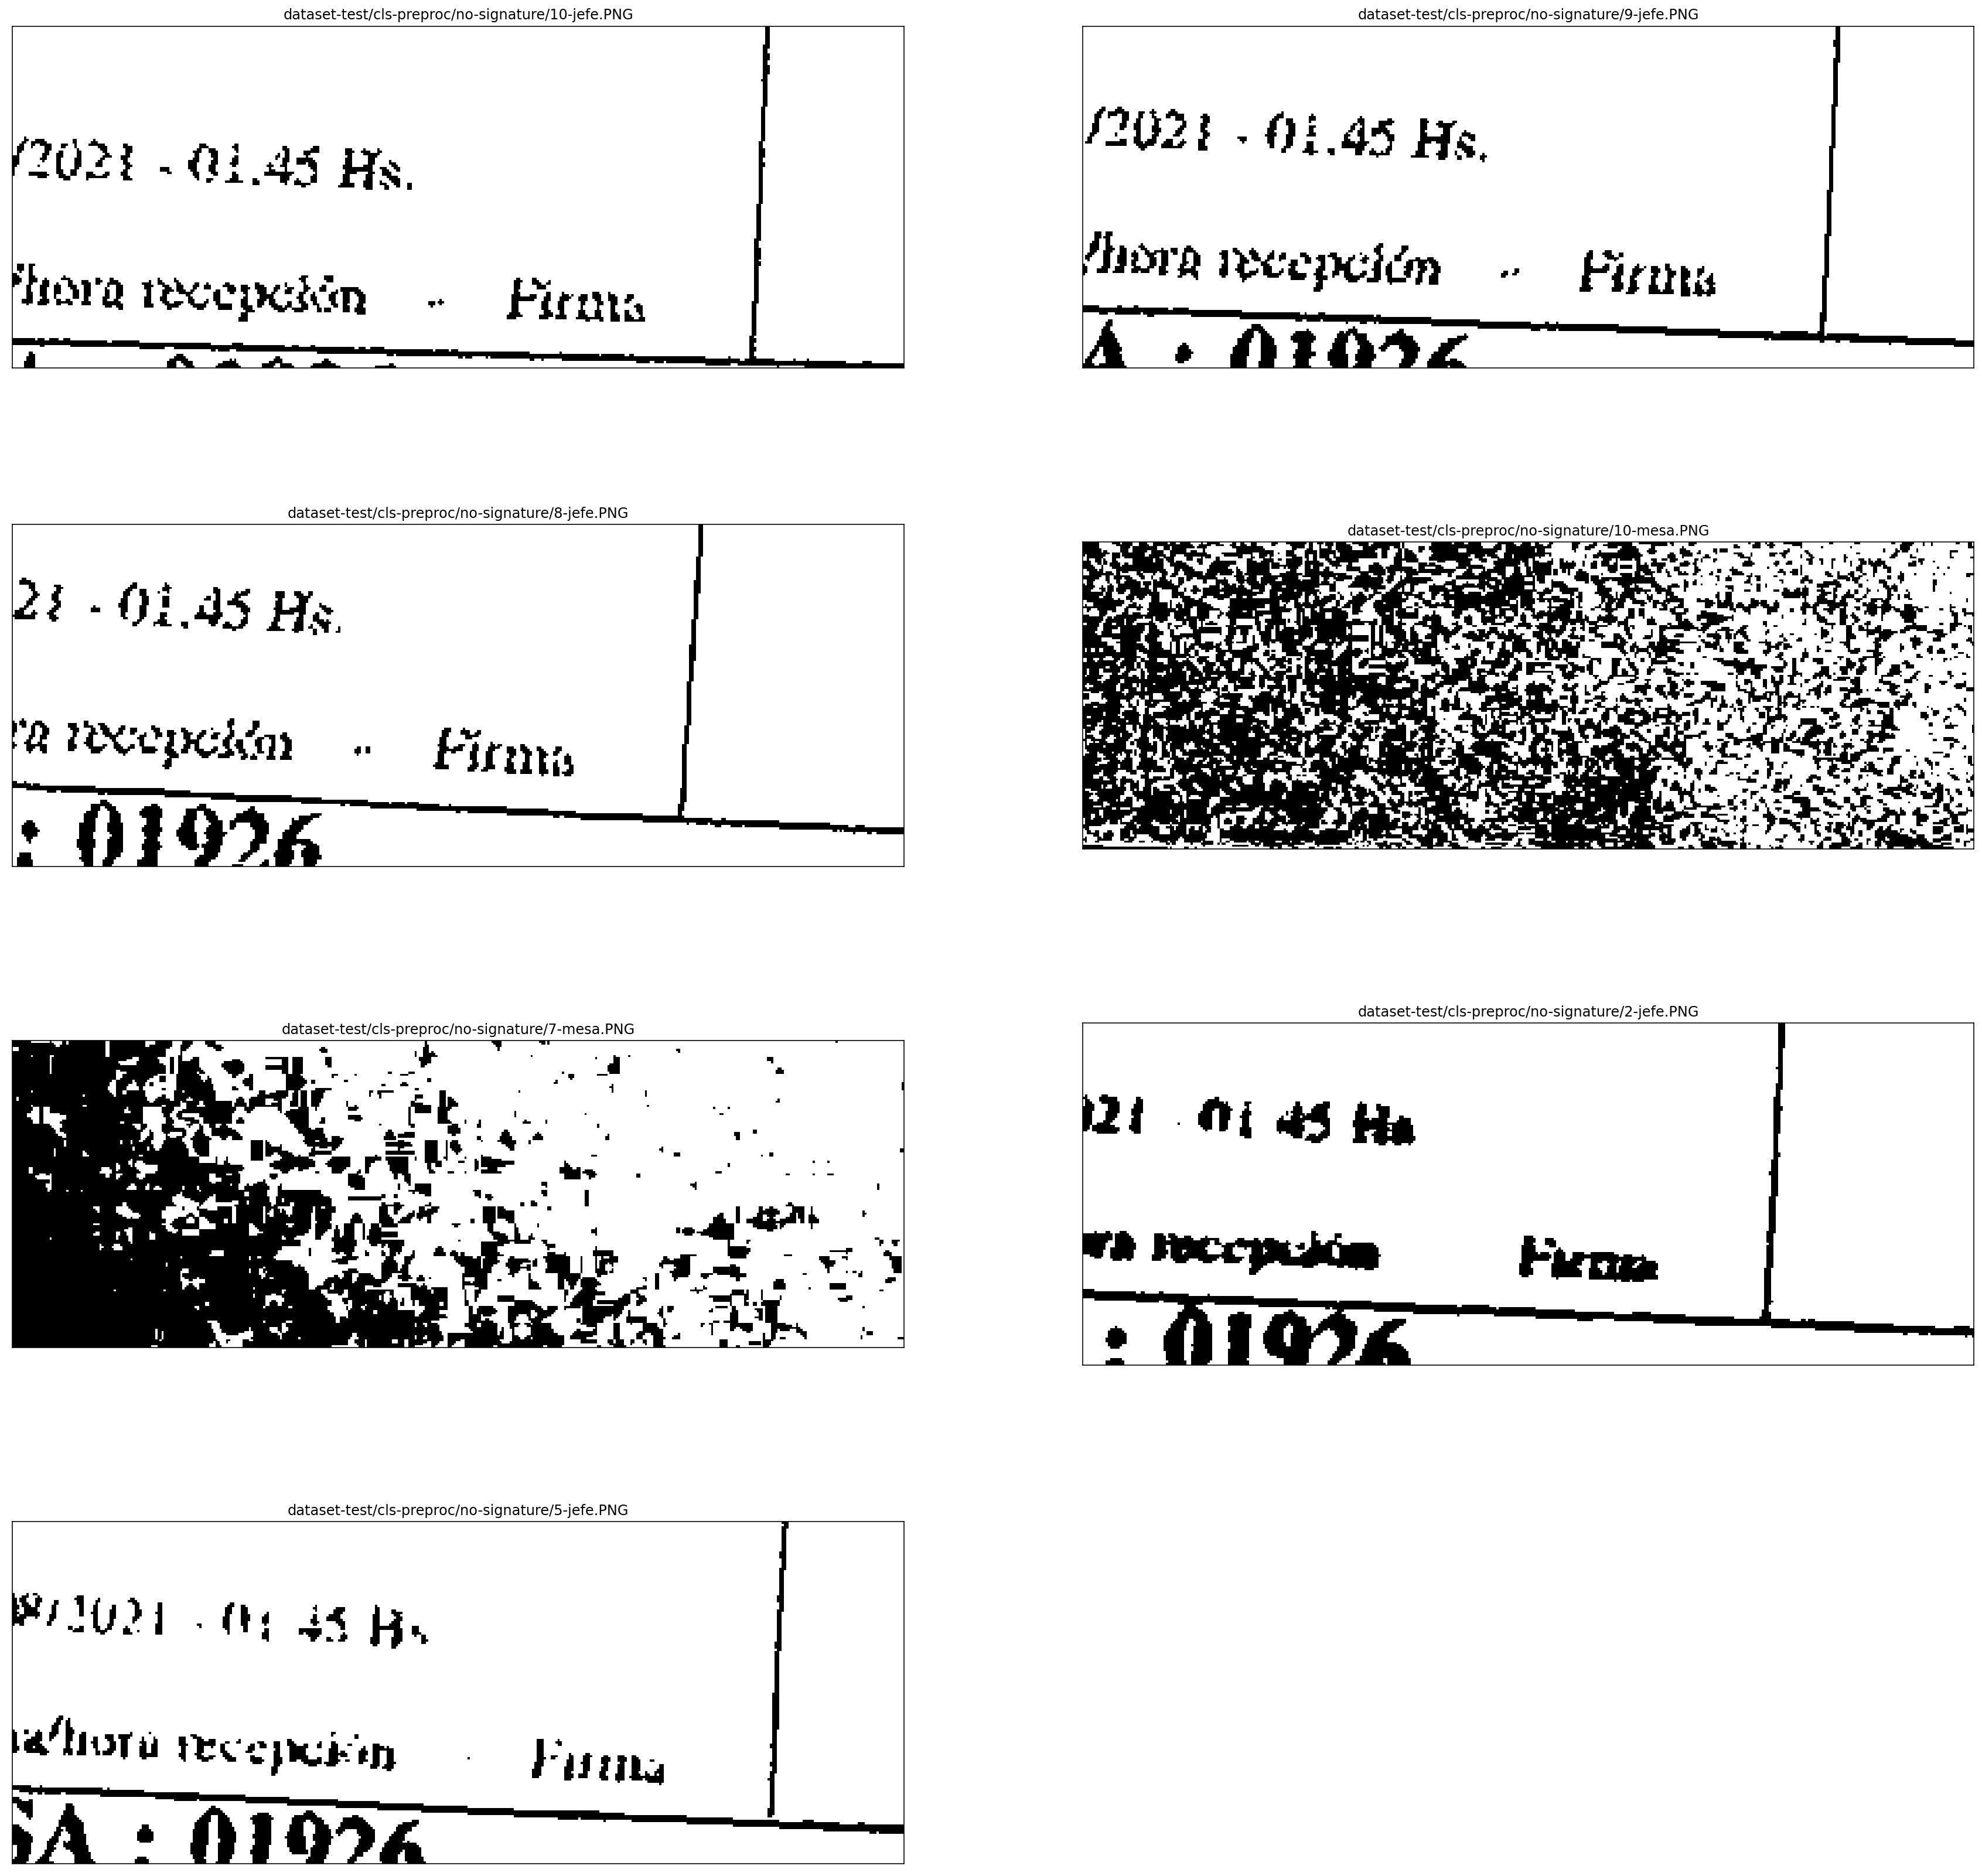

In [50]:
plot_some(no_misconfused,cnt=20)